> **Legacy.** This notebook reads the event-segmented review samples (`review_events_json`) and artifacts built from them, not the detail-segmented stories used by the current experiments. See `docs/data_lineage.md`.

# Word-concept clusters (AoA lexicon) → story/event age distributions

This notebook builds **word-level concept clusters** from a pretrained embedding (GloVe/fastText-like), then applies the **same embedding space** to your event/story texts (by averaging word vectors) to estimate, for each concept cluster, the **Amazon/story age distribution** where that concept appears.

Two age sources stay separate:
- **AoA (lexicon age):** human AoA rating per word/lemma.
- **Story reading age (Amazon):** `age_mid` per story (from `master_batch1`).

Outputs:
- `results/features/eda/concept_age/word_clusters.csv` (word → cluster + AoA)
- `results/features/eda/concept_age/cluster_summary.csv` (cluster stats + top words)
- `results/features/eda/concept_age/story_concept_counts.csv` (story_id × cluster counts)
- `results/features/eda/concept_age/concept_age_summary.csv` (cluster → age distribution summary)


In [1]:
import os
os.chdir('/Users/tzl/repos/story-features')
print('cwd:', os.getcwd())


cwd: /Users/tzl/repos/story-features


In [2]:
from __future__ import annotations

import json
import math
import re
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')


## Load AoA lexicon (lemma-first)

Prefers `data/aoa/AoA_51715_words.xlsx` and lemma-based AoA columns when present.


In [3]:
def load_aoa_lexicon() -> tuple[Path, pd.DataFrame]:
    candidates = [
        Path('data/aoa/AoA_51715_words.xlsx'),
        Path('data/aoa/AoA_ratings_Kuperman_et_al_BRM_with_PoS.xlsx'),
    ]
    p = next((x for x in candidates if x.exists()), None)
    if p is None:
        raise FileNotFoundError('No AoA lexicon found under data/aoa/')
    df = pd.read_excel(p)
    return p, df


aoa_path, aoa_df = load_aoa_lexicon()
print('AoA loaded:', aoa_path, aoa_df.shape)
aoa_df.columns


AoA loaded: data/aoa/AoA_51715_words.xlsx (51715, 16)


Index(['Word', 'Alternative.spelling', 'Freq_pm', 'Dom_PoS_SUBTLEX',
       'Nletters', 'Nphon', 'Nsyll', 'Lemma_highest_PoS', 'AoA_Kup',
       'Perc_known', 'AoA_Kup_lem', 'Perc_known_lem', 'AoA_Bird_lem',
       'AoA_Bristol_lem', 'AoA_Cort_lem', 'AoA_Schock'],
      dtype='object')

In [4]:
def guess_cols(df: pd.DataFrame) -> tuple[str, str]:
    cols = list(df.columns)
    norm = {c: str(c).strip().lower() for c in cols}

    lemma_cols = [c for c in cols if norm[c] == 'lemma' or 'lemma' in norm[c]]
    word_cols = [c for c in cols if norm[c] in {'word', 'wordform', 'word_form'}]
    word_col = lemma_cols[0] if lemma_cols else (word_cols[0] if word_cols else cols[0])

    age_pref = ['aoa_kup_lem', 'aoa_kup', 'rating.mean', 'rating_mean', 'aoa']
    age_col = None
    for want in age_pref:
        for c in cols:
            if norm[c] == want:
                age_col = c
                break
        if age_col:
            break
    if age_col is None:
        for c in cols:
            if pd.to_numeric(df[c], errors='coerce').notna().any():
                age_col = c
                break
    if age_col is None:
        raise ValueError('Could not infer AoA age column')
    return word_col, age_col


word_col, age_col = guess_cols(aoa_df)
print('Using word_col:', word_col)
print('Using age_col: ', age_col)

aoa = aoa_df[[word_col, age_col]].copy()
aoa = aoa.rename(columns={word_col: 'lemma', age_col: 'aoa'})
aoa['lemma'] = aoa['lemma'].astype(str).str.lower().str.strip()
aoa['aoa'] = pd.to_numeric(aoa['aoa'], errors='coerce')
aoa = aoa[aoa['lemma'].str.match(r'^[a-z]+$') & aoa['aoa'].notna()].drop_duplicates('lemma')
aoa.describe(include='all').head(2)


Using word_col: Lemma_highest_PoS
Using age_col:  AoA_Kup_lem


,lemma,aoa
count,31104,31104.0
unique,31104,NaN


## Load pretrained word vectors

Default uses `gensim.downloader` to load a small GloVe model. If you want fully offline, replace this cell to load a local embedding file.


In [5]:
EMBEDDING_NAME = 'glove-wiki-gigaword-100'

import gensim.downloader as api
wv = api.load(EMBEDDING_NAME)
print('loaded embedding:', EMBEDDING_NAME, 'dim=', wv.vector_size)


loaded embedding: glove-wiki-gigaword-100 dim= 100


## Build AoA word matrix + cluster into concepts

We cluster **AoA lemmas** in embedding space. Clusters become our post-hoc "concepts".


In [6]:
in_vocab = aoa['lemma'].apply(lambda w: w in wv)
aoa2 = aoa[in_vocab].copy()
print('AoA lemmas in embedding vocab:', len(aoa2), '/', len(aoa))

X = np.vstack([wv[w] for w in aoa2['lemma'].tolist()]).astype(np.float32)
y_aoa = aoa2['aoa'].to_numpy(dtype=np.float32)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sc = StandardScaler(with_mean=True, with_std=True)
Xz = sc.fit_transform(X)

K = 25
km = KMeans(n_clusters=K, random_state=0, n_init='auto')
lab = km.fit_predict(Xz)

word_clusters = pd.DataFrame({
    'lemma': aoa2['lemma'].tolist(),
    'aoa': y_aoa,
    'cluster': lab,
})
word_clusters.head()


AoA lemmas in embedding vocab: 29163 / 31104


,lemma,aoa,cluster
0,a,2.893384,1
1,aardvark,9.890000,13
2,abacus,8.690000,21
3,abalone,12.230000,13
4,abandon,8.320000,15


In [7]:
# Cluster summaries with representative words
word_clusters['aoa'] = pd.to_numeric(word_clusters['aoa'], errors='coerce')

summ = (
    word_clusters.groupby('cluster')
      .agg(n_words=('lemma','size'), mean_aoa=('aoa','mean'), std_aoa=('aoa','std'))
      .reset_index()
      .sort_values('mean_aoa')
)

def top_words_for_cluster(c, n=14):
    g = word_clusters[word_clusters['cluster']==c].copy()
    # show a mix of early and late within the cluster for interpretability
    g = g.sort_values('aoa')
    a = g['lemma'].head(n//2).tolist()
    b = g['lemma'].tail(n - n//2).tolist()
    return ', '.join(a + b)

summ['example_words'] = summ['cluster'].apply(top_words_for_cluster)
summ.head(10)


,cluster,n_words,mean_aoa,std_aoa,example_words
1,1,1033,6.514081,2.047210,"mom, yes, dad, count, mother, my, no, virtuall..."
4,4,714,8.650331,3.411793,"spoon, carrot, snack, eat, cake, chicken, oran..."
9,9,576,8.932064,2.622131,"jump, ball, leg, lap, cup, butt, plate, isthmi..."
19,19,967,9.323294,3.068445,"shoe, nose, toe, neck, clothes, hair, yellow, ..."
11,11,674,9.586924,2.846597,"water, wet, sun, hill, mouth, rain, cloud, geo..."
0,0,597,9.587261,2.680040,"fly, fire, arm, car, kitty, nighttime, truck, ..."
3,3,593,9.794170,2.961442,"birthday, house, head, chair, friend, brother,..."
16,16,727,9.856660,2.843594,"toy, cartoon, soap, rock, sing, tv, movie, lex..."
14,14,831,9.931391,2.980344,"bed, bathroom, door, bathtub, bath, backyard, ..."
13,13,1042,10.051270,3.188817,"dog, animal, flower, puppy, spider, duck, bird..."


## Load master + event texts (story reading age)

Now we map story/event text into the **same word-vector space** by averaging lemma vectors. Then we assign events to the nearest cluster centroid and compute **story age distributions per concept**.


In [8]:
def read_master() -> tuple[Path, pd.DataFrame]:
    candidates = [
        Path('data/processed/master_batch1.csv.gz'),
        Path('data/processed/master_batch1.parquet'),
        Path('data/processed/master_stories.csv.gz'),
        Path('data/processed/master_stories.parquet'),
    ]
    p = next((x for x in candidates if x.exists()), None)
    if p is None:
        raise FileNotFoundError('No master found under data/processed/')
    if p.suffix == '.parquet':
        df = pd.read_parquet(p)
    else:
        df = pd.read_csv(p, low_memory=False)
    return p, df


path, master = read_master()
master['age_mid'] = pd.to_numeric(master.get('age_mid'), errors='coerce')
work = master[(master.get('review_events_json').notna()) & (master['age_mid'].notna())].copy()
print('Loaded:', path, master.shape)
print('Stories with events + age_mid:', len(work))


Loaded: data/processed/master_batch1.csv.gz (2811, 555)
Stories with events + age_mid: 333


In [9]:
def _safe_json_loads(x):
    if x is None:
        return None
    if isinstance(x, float) and np.isnan(x):
        return None
    if isinstance(x, (dict, list)):
        return x
    s = str(x).strip()
    if not s or s.lower() == 'nan':
        return None
    try:
        return json.loads(s)
    except Exception:
        return None


def iter_event_texts(review_events_json):
    events = _safe_json_loads(review_events_json)
    if not isinstance(events, list):
        return
    for e in events:
        if not isinstance(e, dict):
            continue
        sents = e.get('sentences')
        if not isinstance(sents, list):
            continue
        parts = []
        for s in sents:
            if isinstance(s, dict) and 'text' in s:
                parts.append(str(s['text']))
            elif isinstance(s, str):
                parts.append(s)
        txt = ' '.join(p.strip() for p in parts if p and str(p).strip()).strip()
        if txt:
            yield txt


WORD_RE = re.compile(r"[A-Za-z']+")
try:
    import spacy
    _nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
    def lemmatize(text: str) -> list[str]:
        doc = _nlp(text)
        out=[]
        for t in doc:
            if not t.is_alpha:
                continue
            if t.is_stop:
                continue
            lem = (t.lemma_ or '').lower().strip()
            if lem and lem != '-pron-':
                out.append(lem)
        return out
    print('Using spaCy lemmatizer')
except Exception as e:
    def _lemma_heuristic(w: str) -> str:
        w = w.lower().strip("'")
        for suf in ['ing','ed','ies','s']:
            if len(w) > 4 and w.endswith(suf):
                if suf == 'ies':
                    return w[:-3] + 'y'
                if suf == 's':
                    return w[:-1]
                return w[:-len(suf)]
        return w
    def lemmatize(text: str) -> list[str]:
        toks = [t.lower() for t in WORD_RE.findall(text)]
        toks = [t for t in toks if len(t) >= 2]
        return [_lemma_heuristic(t) for t in toks]
    print('Using heuristic lemmatizer:', repr(e)[:160])


Using heuristic lemmatizer: ModuleNotFoundError("No module named 'spacy'")


## Build IDF weights over event corpus (for better event embeddings)

We compute an IDF over events and use an **IDF-weighted mean** of word vectors per event.


In [10]:
event_docs = []
event_meta = []

for row in work.itertuples(index=False):
    sid = getattr(row, 'story_id', None)
    age = float(getattr(row, 'age_mid'))
    for ev_i, ev_txt in enumerate(iter_event_texts(getattr(row, 'review_events_json'))):
        toks = [t for t in lemmatize(ev_txt) if t in wv]
        if len(toks) < 5:
            continue
        event_docs.append(toks)
        event_meta.append({'story_id': sid, 'age_mid': age, 'event': ev_i})

print('events:', len(event_docs))

# doc frequency
dfreq = Counter()
for toks in event_docs:
    dfreq.update(set(toks))
N = len(event_docs)
idf = {w: math.log((N + 1) / (dfreq[w] + 1)) + 1.0 for w in dfreq}

def embed_event(toks: list[str]) -> np.ndarray:
    ws = [w for w in toks if w in wv]
    if not ws:
        return None
    weights = np.array([idf.get(w, 1.0) for w in ws], dtype=np.float32)
    vecs = np.vstack([wv[w] for w in ws]).astype(np.float32)
    v = (vecs * weights[:,None]).sum(axis=0) / (weights.sum() + 1e-12)
    return v

event_X = np.vstack([embed_event(t) for t in event_docs])
event_meta_df = pd.DataFrame(event_meta)
event_X.shape, event_meta_df.shape


events: 3539


((3539, 100), (3539, 3))

## Assign events to nearest word-concept cluster

We assign each event embedding to the nearest KMeans centroid (in standardized space).


In [11]:
# Standardize event vectors using the same scaler used for word clustering
event_Xz = sc.transform(event_X)

# nearest centroid assignment
event_cluster = km.predict(event_Xz)
event_meta_df['cluster'] = event_cluster

event_meta_df.head()


,story_id,age_mid,event,cluster
0,10265.0,6.0,0,1
1,10265.0,6.0,1,1
2,10265.0,6.0,2,1
3,10265.0,6.0,3,1
4,10265.0,6.0,4,1


## Concept age distributions (story-level)

We count concept occurrences per story and summarize each concept’s story-age distribution.


In [12]:
story_concept = (
    event_meta_df.groupby(['story_id','cluster'])
      .size()
      .reset_index(name='n_events')
)

story_age = event_meta_df.groupby('story_id', as_index=False).agg(age_mid=('age_mid','first'))
story_concept = story_concept.merge(story_age, on='story_id', how='left')

def concept_age_summary(df: pd.DataFrame) -> pd.DataFrame:
    rows=[]
    for c, g in df.groupby('cluster'):
        ages = g['age_mid'].to_numpy(dtype=float)
        rows.append({
            'cluster': int(c),
            'n_stories': int(g['story_id'].nunique()),
            'n_events_total': int(g['n_events'].sum()),
            'age_mean': float(np.mean(ages)),
            'age_median': float(np.median(ages)),
            'age_p10': float(np.quantile(ages, 0.10)),
            'age_p90': float(np.quantile(ages, 0.90)),
        })
    return pd.DataFrame(rows).sort_values('age_median')


age_summ = concept_age_summary(story_concept)
age_summ.head(10)


,cluster,n_stories,n_events_total,age_mean,age_median,age_p10,age_p90
0,0,1,1,3.000000,3.00,3.00,3.00
5,13,6,17,3.833333,3.75,2.25,5.50
3,4,7,7,4.214286,4.00,3.30,5.70
9,22,17,18,4.470588,4.00,3.00,6.20
4,11,4,6,5.375000,4.50,4.50,6.95
8,21,1,1,4.500000,4.50,4.50,4.50
1,1,330,3478,5.153030,5.00,3.00,7.00
7,19,2,2,5.000000,5.00,4.20,5.80
2,3,5,5,5.300000,5.50,4.40,6.00
6,16,4,4,5.125000,5.50,3.05,6.90


In [13]:
# Join word examples for interpretability
age_summ2 = age_summ.merge(summ[['cluster','mean_aoa','example_words']], on='cluster', how='left')
age_summ2.head(12)


,cluster,n_stories,n_events_total,age_mean,age_median,age_p10,age_p90,mean_aoa,example_words
0,0,1,1,3.000000,3.00,3.00,3.00,9.587261,"fly, fire, arm, car, kitty, nighttime, truck, ..."
1,13,6,17,3.833333,3.75,2.25,5.50,10.051270,"dog, animal, flower, puppy, spider, duck, bird..."
2,4,7,7,4.214286,4.00,3.30,5.70,8.650331,"spoon, carrot, snack, eat, cake, chicken, oran..."
3,22,17,18,4.470588,4.00,3.00,6.20,10.288249,"momma, mama, potty, ouch, mommy, nap, daddy, m..."
4,11,4,6,5.375000,4.50,4.50,6.95,9.586924,"water, wet, sun, hill, mouth, rain, cloud, geo..."
5,21,1,1,4.500000,4.50,4.50,4.50,10.897670,"pinkie, finger, popsicle, boot, lamp, tricycle..."
6,1,330,3478,5.153030,5.00,3.00,7.00,6.514081,"mom, yes, dad, count, mother, my, no, virtuall..."
7,19,2,2,5.000000,5.00,4.20,5.80,9.323294,"shoe, nose, toe, neck, clothes, hair, yellow, ..."
8,3,5,5,5.300000,5.50,4.40,6.00,9.794170,"birthday, house, head, chair, friend, brother,..."
9,16,4,4,5.125000,5.50,3.05,6.90,9.856660,"toy, cartoon, soap, rock, sing, tv, movie, lex..."


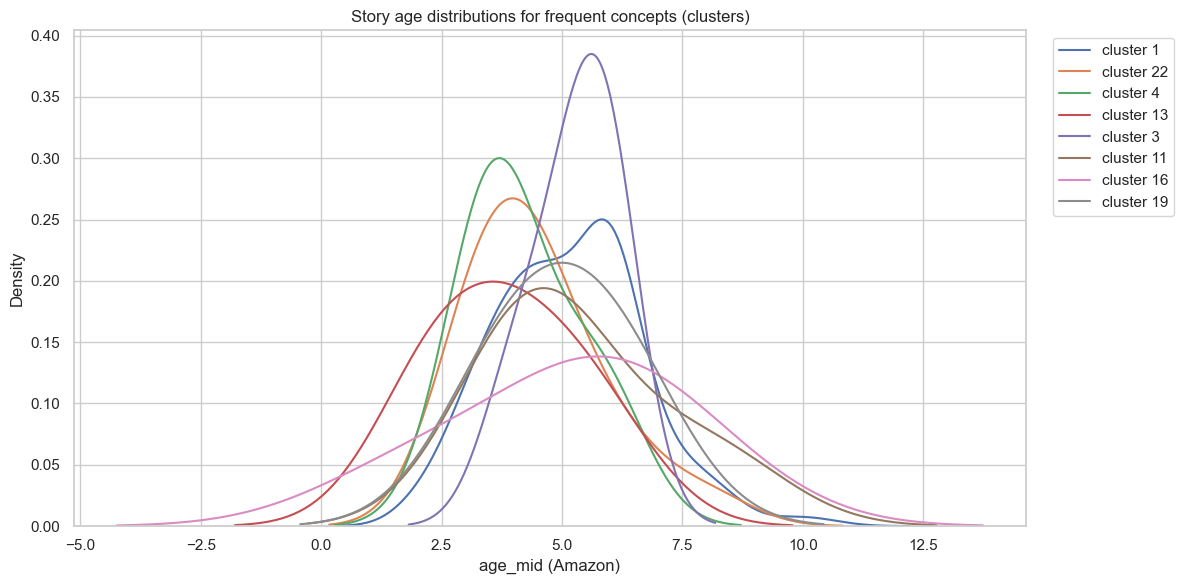

In [14]:
# Plot a few concepts by age distribution
top = age_summ2.sort_values('n_stories', ascending=False).head(8)['cluster'].tolist()
plt.figure(figsize=(12,6))
for c in top:
    ages = story_concept[story_concept['cluster']==c]['age_mid']
    sns.kdeplot(ages, label=f'cluster {c}', bw_adjust=1.2)
plt.title('Story age distributions for frequent concepts (clusters)')
plt.xlabel('age_mid (Amazon)')
plt.legend(bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()


## Save artifacts (CSV)

These CSVs can be labeled later (e.g., send `example_words` to an LLM for a short concept name/description).


In [15]:
out_dir = Path('results/features/eda/concept_age')
out_dir.mkdir(parents=True, exist_ok=True)

word_clusters.to_csv(out_dir / 'word_clusters.csv', index=False)
summ.to_csv(out_dir / 'cluster_summary.csv', index=False)
story_concept.to_csv(out_dir / 'story_concept_counts.csv', index=False)
age_summ2.to_csv(out_dir / 'concept_age_summary.csv', index=False)

print('Wrote:', out_dir / 'word_clusters.csv')
print('Wrote:', out_dir / 'cluster_summary.csv')
print('Wrote:', out_dir / 'story_concept_counts.csv')
print('Wrote:', out_dir / 'concept_age_summary.csv')


Wrote: results/features/eda/concept_age/word_clusters.csv
Wrote: results/features/eda/concept_age/cluster_summary.csv
Wrote: results/features/eda/concept_age/story_concept_counts.csv
Wrote: results/features/eda/concept_age/concept_age_summary.csv


## Post-hoc LLM labels (optional)

This is a GemmaScope-style *interpretability* step: use an open-source LLM to assign short human-readable labels to each cluster based on its representative words.

- Default is **OFF** (writes prompts only).
- Turn `RUN_LLM=True` to generate labels locally (may require a GPU / lots of RAM depending on model).


In [16]:
from pathlib import Path
import json
import re
import pandas as pd

out_dir = Path('results/features/eda/concept_age')
out_dir.mkdir(parents=True, exist_ok=True)
df = age_summ2['cluster','n_stories','age_median','example_words']
df = df.dropna(subset=['example_words']).copy()
df['example_words'] = df['example_words'].astype(str)

RUN_LLM = False
MODEL_NAME = os.environ.get('CONCEPT_LABEL_MODEL', '').strip()
# Example: export CONCEPT_LABEL_MODEL='gpt-oss' (or a local HF model path you have cached)

def make_prompt(row: pd.Series) -> str:
    words = row['example_words']
    header = {k: row[k] for k in row.index if k != 'example_words'}
    return (
        'You are labeling a semantic cluster of words.\n'
        'Task: Provide a short concept label and 1-sentence description.\n'
        'Return STRICT JSON with keys: label, description, keywords (list of strings).\n'
        f'Cluster metadata: {header}\n'
        f'Representative words: {words}\n'
    )

prompts = []
for _, row in df.iterrows():
    prompts.append({
        'cluster': int(row['cluster']),
        'prompt': make_prompt(row),
    })
prompts_path = out_dir / 'label_prompts.jsonl'
with prompts_path.open('w', encoding='utf-8') as f:
    for p in prompts:
        f.write(json.dumps(p, ensure_ascii=False) + "\n")
print('Wrote prompts:', prompts_path, 'n=', len(prompts))

if not RUN_LLM:
    print('RUN_LLM=False: skipping generation. Set RUN_LLM=True and CONCEPT_LABEL_MODEL to run.')
else:
    if not MODEL_NAME:
        raise ValueError('Set CONCEPT_LABEL_MODEL to an open-source LLM name/path (and ensure transformers/torch are installed).')
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer

    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    mdl = AutoModelForCausalLM.from_pretrained(MODEL_NAME, device_map="auto")
    mdl.eval()

    def generate(prompt: str) -> str:
        inputs = tok(prompt, return_tensors="pt")
        # move to model device (device_map=auto)
        dev = next(mdl.parameters()).device
        inputs = {k: v.to(dev) for k, v in inputs.items()}
        with torch.no_grad():
            out = mdl.generate(**inputs, max_new_tokens=180, do_sample=False)
        txt = tok.decode(out[0], skip_special_tokens=True)
        return txt[len(prompt):].strip()

rows=[]
for p in prompts:
    raw = generate(p['prompt'])
    # extract first JSON object in the output
    m = re.search(r"\{.*\}", raw, flags=re.S)
    if not m:
        rows.append({'cluster': p['cluster'], 'raw': raw, 'label': '', 'description': '', 'keywords': ''})
        continue
    try:
        obj = json.loads(m.group(0))
    except Exception:
        rows.append({'cluster': p['cluster'], 'raw': raw, 'label': '', 'description': '', 'keywords': ''})
        continue
    rows.append({
        'cluster': p['cluster'],
        'label': str(obj.get('label','')).strip(),
        'description': str(obj.get('description','')).strip(),
        'keywords': json.dumps(obj.get('keywords', []), ensure_ascii=False),
        'raw': raw,
    })

labels = pd.DataFrame(rows)
labels_path = out_dir / 'concept_labels.csv'
labels.to_csv(labels_path, index=False)
print('Wrote labels:', labels_path)
labels.head()


KeyError: ('cluster', 'n_stories', 'age_median', 'example_words')

## Quantitative tests (no Moran's I)

These summarize how strongly the 2D concept space relates to the age variable, without relying on visual inspection.

- CV **R²** for predicting age from 2D coords (ridge + kNN).
- **Local smoothness**: average variance of age among k nearest neighbors in 2D.
- **Kruskal–Wallis** test of age differences across clusters + effect size.


In [ ]:
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Build a story-level concept-mixture feature matrix and project to 2D with PCA
from sklearn.decomposition import PCA
wide = story_concept.pivot_table(index="story_id", columns="cluster", values="n_events", fill_value=0)
age_map = story_concept.groupby("story_id", as_index=True)["age_mid"].first()
wide = wide.loc[age_map.index]
Xw = wide.to_numpy(dtype=np.float32)
y = age_map.to_numpy(dtype=np.float32)
Xwz = StandardScaler().fit_transform(Xw)
xy = PCA(n_components=2, random_state=0).fit_transform(Xwz)
df2 = pd.DataFrame({"x": xy[:,0], "y": xy[:,1], "age": y}).copy()
X2 = df2[["x","y"]].to_numpy(dtype=np.float32)
yy = df2["age"].to_numpy(dtype=np.float32)

# CV R2
kf = KFold(n_splits=5, shuffle=True, random_state=0)
pred_r = np.zeros_like(yy, dtype=float)
pred_k = np.zeros_like(yy, dtype=float)
for tr, te in kf.split(X2):
    rr = Ridge(alpha=1.0)
    rr.fit(X2[tr], yy[tr])
    pred_r[te] = rr.predict(X2[te])
    knn = KNeighborsRegressor(n_neighbors=35, weights="distance")
    knn.fit(X2[tr], yy[tr])
    pred_k[te] = knn.predict(X2[te])
print("CV R2 ridge(x,y)->age:", float(r2_score(yy, pred_r)))
print("CV R2 knn(x,y)->age: ", float(r2_score(yy, pred_k)))

# local smoothness: neighbor variance
KNN_K = 25
nbrs = NearestNeighbors(n_neighbors=KNN_K+1).fit(X2)
idx = nbrs.kneighbors(X2, return_distance=False)[:,1:]
neigh_var = np.var(yy[idx], axis=1)
print("mean neighbor age variance (k=25):", float(np.mean(neigh_var)))

from scipy.stats import kruskal

groups = [g["age_mid"].to_numpy(dtype=float) for _, g in story_concept.groupby("cluster")]
stat, p = kruskal(*groups)
n = len(story_concept)
k = story_concept["cluster"].nunique()
eps2 = (stat - k + 1) / (n - k)
print("Kruskal-Wallis H=", float(stat), "p=", float(p), "epsilon^2=", float(eps2))
